<a href="https://colab.research.google.com/github/kbliml/PracAI/blob/main/notebookbd66246188.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [5]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

playground_series_s6e11_path = kagglehub.competition_download('playground-series-s6e11')

print('Data source import complete.')


100%|██████████| 29.5M/29.5M [00:00<00:00, 108MB/s]

Extracting files...


Data source import complete.


In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [7]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = kagglehub.competition_download('playground-series-s6e11')
print("Path to competition files:", path)

train = pd.read_csv(os.path.join(path, 'train.csv'))
test = pd.read_csv(os.path.join(path, 'test.csv'))
submission = pd.read_csv(os.path.join(path, 'sample_submission.csv'))
print('Train:', train.shape, 'Test:', test.shape)
display(train.head())

Path to competition files: /root/.cache/kagglehub/competitions/playground-series-s6e11
Train: (699960, 26) Test: (299984, 25)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


Missing values: 0
is_fraud
0.0    98.33
1.0     1.67
Name: proportion, dtype: float64


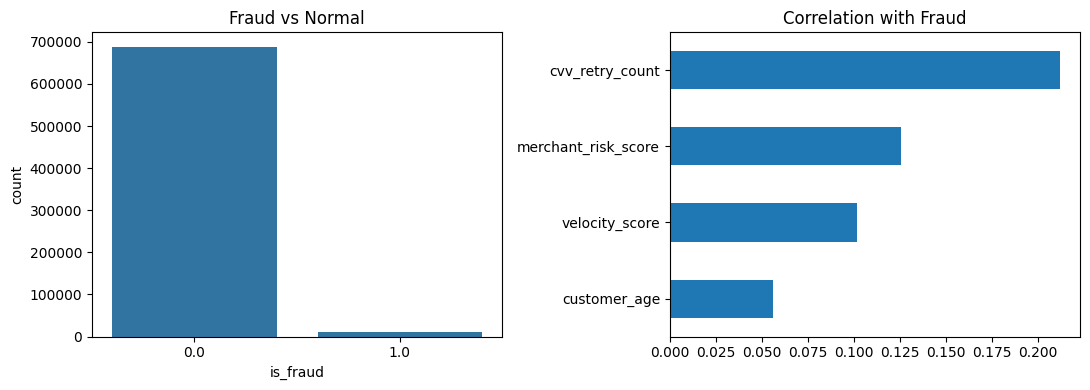

In [8]:
print("Missing values:", train.isna().sum().sum())
print(train["is_fraud"].value_counts(normalize=True).mul(100).round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=train, x="is_fraud", ax=ax[0])
ax[0].set_title("Fraud vs Normal")

features = ["merchant_risk_score", "velocity_score", "cvv_retry_count", "customer_age"]
correlations = train[features + ["is_fraud"]].corr(numeric_only=True)["is_fraud"].drop("is_fraud")
correlations.sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Correlation with Fraud")
plt.tight_layout()
plt.show()

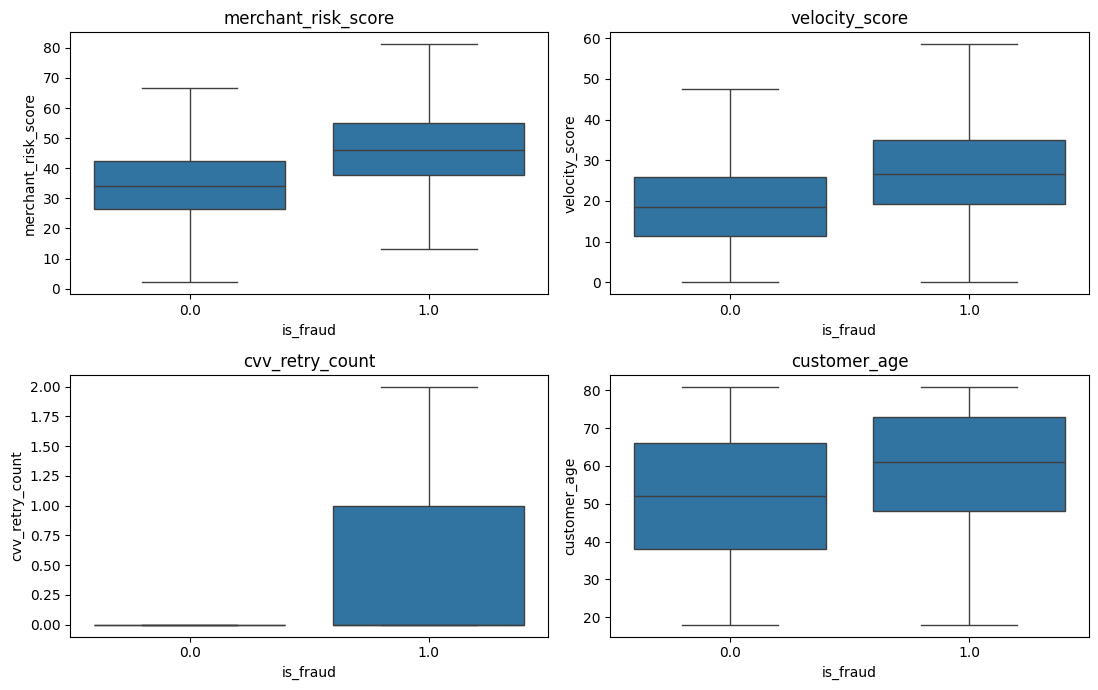

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(features, axes.flat):
    sns.boxplot(data=train, x="is_fraud", y=feature, showfliers=False, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

In [10]:
def add_features(df, digits=False):
    df = df.copy()
    df['risk_interaction'] = df['merchant_risk_score'] * df['velocity_score']
    df['merchant_risk_squared'] = df['merchant_risk_score'] ** 2
    df['velocity_squared'] = df['velocity_score'] ** 2
    df['risk_cvv_interaction'] = df['merchant_risk_score'] * df['cvv_retry_count']
    df['amount_log'] = np.log1p(df['amount_usd'].clip(lower=0))
    df['foreign_vpn'] = df['is_foreign_transaction'].astype(int) * df['used_vpn'].astype(int)
    if digits:
        for col in ['amount_usd', 'account_balance_usd', 'merchant_risk_score', 'velocity_score']:
            x = df[col].abs().astype(float)
            whole = np.floor(x)
            cents = np.rint(x * 100) % 100
            power = np.floor(np.log10(x.where(x > 0, 1)))
            df[col + '_integer'] = whole
            df[col + '_fraction'] = cents
            df[col + '_first_digit'] = np.floor(x / np.power(10.0, power) + 1e-9)
            df[col + '_integer_digits'] = np.floor(np.log10(whole.clip(lower=1))) + 1
    return df

X = train.drop(columns=['id', 'is_fraud'])
y = train['is_fraud'].astype(int)
X_test = test.drop(columns=['id'])

In [11]:
import tensorflow as tf
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix
import gc

SEED = 42

In [12]:
def make_preprocess(X):
    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.columns.difference(numeric).tolist()
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32))]), categorical)
    ])

In [13]:
def build_model(n_features, bn=False):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(n_features,))])
    for units, dropout in [(128, .3), (64, .2), (32, 0)]:
        model.add(tf.keras.layers.Dense(units, use_bias=not (bn and units != 32)))
        if bn and units != 32:
            model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Activation('relu'))
        if dropout:
            model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001), loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return model

In [14]:
def run_model(Xa, Xb, ya, yb, config, Xt=None, seed=42):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    prep = make_preprocess(Xa)
    a = prep.fit_transform(Xa).astype('float32')
    b = prep.transform(Xb).astype('float32')
    model = build_model(a.shape[1], config['bn'])
    if config['weight'] == 'balanced':
        w = compute_class_weight('balanced', classes=np.array([0, 1]), y=ya)
        weights = dict(enumerate(w.astype(float)))
    else:
        weights = {0: 1., 1: float(config['weight'])}
    callbacks = []
    if config['lr']:
        callbacks.append(tf.keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=.5, patience=2, min_lr=1e-5))
    callbacks.append(tf.keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=5, restore_best_weights=True))
    history = model.fit(a, ya, validation_data=(b, yb), epochs=30, batch_size=512, class_weight=weights, callbacks=callbacks, verbose=2)
    valid = model.predict(b, batch_size=4096, verbose=0).ravel()
    pred = None if Xt is None else model.predict(prep.transform(Xt).astype('float32'), batch_size=4096, verbose=0).ravel()
    return valid, pred, history.history

In [15]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
from itertools import product

def run_tree(name, Xa, Xb, ya, yb, Xt=None, seed=42):
    num = Xa.select_dtypes(include=np.number).columns.tolist()
    cat = Xa.columns.difference(num).tolist()
    prep = ColumnTransformer([('num', SimpleImputer(strategy='median'), num),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore', dtype=np.float32))]), cat)])
    a = prep.fit_transform(Xa).astype('float32')
    b = prep.transform(Xb).astype('float32')
    if name == 'LightGBM':
        model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=.03, num_leaves=4, max_depth=3, random_state=seed, verbosity=-1, n_jobs=4)
        model.fit(a, ya, eval_set=[(b,yb)], eval_metric='auc', callbacks=[lgb.early_stopping(80, verbose=False)])
    else:
        model = xgb.XGBClassifier(n_estimators=2000, learning_rate=.03, max_depth=2, tree_method='hist', eval_metric='auc', early_stopping_rounds=80, random_state=seed, n_jobs=4)
        model.fit(a, ya, eval_set=[(b,yb)], verbose=False)
    return model.predict_proba(b)[:,1], None if Xt is None else model.predict_proba(prep.transform(Xt).astype('float32'))[:,1]

In [16]:
dev, hold = train_test_split(np.arange(len(y)), test_size=.2, stratify=y, random_state=SEED)
base = dict(fe=False, digits=False, bn=False, lr=False, weight='balanced')
combined = dict(fe=True, digits=True, bn=True, lr=True, weight=20)
X_fe = add_features(X, digits=True)
T_fe = add_features(X_test, digits=True)
names = ['Baseline MLP','Combined MLP','LightGBM','XGBoost']

def fit_one(name, a, b, predict_idx=None, final_test=False, seed=42):
    raw = name == 'Baseline MLP'
    data = X if raw else X_fe
    extra = (X_test if raw else T_fe) if final_test else (data.iloc[predict_idx] if predict_idx is not None else None)
    if 'MLP' in name:
        v,t,_ = run_model(data.iloc[a],data.iloc[b],y.iloc[a],y.iloc[b],base if raw else combined,extra,seed)
    else:
        v,t = run_tree(name,data.iloc[a],data.iloc[b],y.iloc[a],y.iloc[b],extra,seed)
    return v,t

def threshold_for(y_true,p):
    precision,recall,thresholds = precision_recall_curve(y_true,p)
    f = 2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    return float(thresholds[np.argmax(f)])

def metrics(name, truth, p, threshold):
    label = p >= threshold
    return {'Model':name,'ROC-AUC':roc_auc_score(truth,p),'AP':average_precision_score(truth,p),'Precision':precision_score(truth,label,zero_division=0),'Recall':recall_score(truth,label,zero_division=0),'F1':f1_score(truth,label,zero_division=0),'Threshold':threshold}


In [18]:
N_FOLDS = 5
skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
oof = {name:np.zeros(len(dev)) for name in names}
held = {name:np.zeros(len(hold)) for name in names}
test_preds = {name:np.zeros(len(test)) for name in names}
for fold,(a,b) in enumerate(skf.split(dev,y.iloc[dev]),1):
    for name in names:
        print('Fold',fold,name)
        raw = name == 'Baseline MLP'
        data = X if raw else X_fe
        extra = pd.concat([data.iloc[hold], X_test if raw else T_fe],ignore_index=True)
        if 'MLP' in name:
            v,t,_ = run_model(data.iloc[dev[a]],data.iloc[dev[b]],y.iloc[dev[a]],y.iloc[dev[b]],base if raw else combined,extra,SEED+fold)
        else:
            v,t = run_tree(name,data.iloc[dev[a]],data.iloc[dev[b]],y.iloc[dev[a]],y.iloc[dev[b]],extra,SEED+fold)
        oof[name][b] = v
        held[name] += t[:len(hold)]/N_FOLDS
        test_preds[name] += t[len(hold):]/N_FOLDS
        print('Fold AUC:',roc_auc_score(y.iloc[dev[b]],v))
        del extra
        gc.collect()


Fold 1 Baseline MLP
Epoch 1/30
875/875 - 8s - 9ms/step - auc: 0.9211 - loss: 0.3566 - val_auc: 0.9414 - val_loss: 0.2672
Epoch 2/30
875/875 - 7s - 9ms/step - auc: 0.9362 - loss: 0.3216 - val_auc: 0.9423 - val_loss: 0.2799
Epoch 3/30
875/875 - 6s - 7ms/step - auc: 0.9402 - loss: 0.3120 - val_auc: 0.9426 - val_loss: 0.2757
Epoch 4/30
875/875 - 8s - 9ms/step - auc: 0.9412 - loss: 0.3098 - val_auc: 0.9423 - val_loss: 0.2877
Epoch 5/30
875/875 - 6s - 7ms/step - auc: 0.9425 - loss: 0.3063 - val_auc: 0.9422 - val_loss: 0.2765
Epoch 6/30
875/875 - 7s - 9ms/step - auc: 0.9435 - loss: 0.3038 - val_auc: 0.9419 - val_loss: 0.2796
Epoch 7/30
875/875 - 6s - 6ms/step - auc: 0.9450 - loss: 0.2999 - val_auc: 0.9419 - val_loss: 0.2736
Epoch 8/30
875/875 - 7s - 9ms/step - auc: 0.9459 - loss: 0.2973 - val_auc: 0.9411 - val_loss: 0.2694
Fold AUC: 0.942683090155832
Fold 1 Combined MLP
Epoch 1/30
875/875 - 9s - 11ms/step - auc: 0.9161 - loss: 0.4041 - val_auc: 0.9399 - val_loss: 0.1664 - learning_rate: 0.001

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold AUC: 0.9456600357360889
Fold 1 XGBoost
Fold AUC: 0.9459401842007173
Fold 2 Baseline MLP
Epoch 1/30
875/875 - 8s - 9ms/step - auc: 0.9205 - loss: 0.3582 - val_auc: 0.9430 - val_loss: 0.2911
Epoch 2/30
875/875 - 8s - 9ms/step - auc: 0.9370 - loss: 0.3198 - val_auc: 0.9441 - val_loss: 0.2837
Epoch 3/30
875/875 - 6s - 7ms/step - auc: 0.9393 - loss: 0.3138 - val_auc: 0.9445 - val_loss: 0.2925
Epoch 4/30
875/875 - 8s - 9ms/step - auc: 0.9409 - loss: 0.3101 - val_auc: 0.9440 - val_loss: 0.2966
Epoch 5/30
875/875 - 6s - 7ms/step - auc: 0.9419 - loss: 0.3078 - val_auc: 0.9442 - val_loss: 0.2921
Epoch 6/30
875/875 - 7s - 8ms/step - auc: 0.9427 - loss: 0.3055 - val_auc: 0.9442 - val_loss: 0.2908
Epoch 7/30
875/875 - 6s - 7ms/step - auc: 0.9443 - loss: 0.3014 - val_auc: 0.9436 - val_loss: 0.2934
Epoch 8/30
875/875 - 7s - 7ms/step - auc: 0.9454 - loss: 0.2989 - val_auc: 0.9432 - val_loss: 0.2943
Fold AUC: 0.9445564475009892
Fold 2 Combined MLP
Epoch 1/30
875/875 - 11s - 12ms/step - auc: 0.9145

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold AUC: 0.9499946729957498
Fold 2 XGBoost
Fold AUC: 0.9500116616232513
Fold 3 Baseline MLP
Epoch 1/30
875/875 - 9s - 11ms/step - auc: 0.9207 - loss: 0.3580 - val_auc: 0.9436 - val_loss: 0.3322
Epoch 2/30
875/875 - 10s - 12ms/step - auc: 0.9364 - loss: 0.3212 - val_auc: 0.9438 - val_loss: 0.3126
Epoch 3/30
875/875 - 6s - 7ms/step - auc: 0.9394 - loss: 0.3139 - val_auc: 0.9441 - val_loss: 0.3046
Epoch 4/30
875/875 - 7s - 8ms/step - auc: 0.9412 - loss: 0.3096 - val_auc: 0.9436 - val_loss: 0.3145
Epoch 5/30
875/875 - 6s - 7ms/step - auc: 0.9422 - loss: 0.3069 - val_auc: 0.9433 - val_loss: 0.2892
Epoch 6/30
875/875 - 7s - 8ms/step - auc: 0.9436 - loss: 0.3035 - val_auc: 0.9431 - val_loss: 0.2839
Epoch 7/30
875/875 - 6s - 7ms/step - auc: 0.9446 - loss: 0.3007 - val_auc: 0.9435 - val_loss: 0.2789
Epoch 8/30
875/875 - 11s - 13ms/step - auc: 0.9455 - loss: 0.2985 - val_auc: 0.9432 - val_loss: 0.2882
Fold AUC: 0.9442085367902572
Fold 3 Combined MLP
Epoch 1/30
875/875 - 9s - 11ms/step - auc: 0.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold AUC: 0.9501482364117869
Fold 3 XGBoost
Fold AUC: 0.9500568779966765
Fold 4 Baseline MLP
Epoch 1/30
875/875 - 8s - 10ms/step - auc: 0.9218 - loss: 0.3553 - val_auc: 0.9321 - val_loss: 0.3276
Epoch 2/30
875/875 - 7s - 9ms/step - auc: 0.9394 - loss: 0.3143 - val_auc: 0.9337 - val_loss: 0.3326
Epoch 3/30
875/875 - 6s - 7ms/step - auc: 0.9425 - loss: 0.3065 - val_auc: 0.9339 - val_loss: 0.3065
Epoch 4/30
875/875 - 7s - 9ms/step - auc: 0.9440 - loss: 0.3025 - val_auc: 0.9342 - val_loss: 0.3194
Epoch 5/30
875/875 - 9s - 10ms/step - auc: 0.9445 - loss: 0.3011 - val_auc: 0.9345 - val_loss: 0.3171
Epoch 6/30
875/875 - 8s - 9ms/step - auc: 0.9458 - loss: 0.2978 - val_auc: 0.9339 - val_loss: 0.3115
Epoch 7/30
875/875 - 6s - 7ms/step - auc: 0.9469 - loss: 0.2949 - val_auc: 0.9334 - val_loss: 0.3179
Epoch 8/30
875/875 - 8s - 9ms/step - auc: 0.9482 - loss: 0.2912 - val_auc: 0.9326 - val_loss: 0.3075
Epoch 9/30
875/875 - 6s - 7ms/step - auc: 0.9487 - loss: 0.2898 - val_auc: 0.9320 - val_loss: 0.3

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold AUC: 0.9392113271883006
Fold 4 XGBoost
Fold AUC: 0.9392831258542648
Fold 5 Baseline MLP
Epoch 1/30
875/875 - 9s - 11ms/step - auc: 0.9188 - loss: 0.3623 - val_auc: 0.9408 - val_loss: 0.2772
Epoch 2/30
875/875 - 6s - 7ms/step - auc: 0.9368 - loss: 0.3202 - val_auc: 0.9423 - val_loss: 0.2776
Epoch 3/30
875/875 - 8s - 9ms/step - auc: 0.9392 - loss: 0.3147 - val_auc: 0.9425 - val_loss: 0.2903
Epoch 4/30
875/875 - 6s - 7ms/step - auc: 0.9413 - loss: 0.3090 - val_auc: 0.9427 - val_loss: 0.2798
Epoch 5/30
875/875 - 10s - 12ms/step - auc: 0.9422 - loss: 0.3068 - val_auc: 0.9424 - val_loss: 0.2688
Epoch 6/30
875/875 - 7s - 8ms/step - auc: 0.9433 - loss: 0.3038 - val_auc: 0.9425 - val_loss: 0.2801
Epoch 7/30
875/875 - 9s - 10ms/step - auc: 0.9448 - loss: 0.3000 - val_auc: 0.9418 - val_loss: 0.2751
Epoch 8/30
875/875 - 8s - 9ms/step - auc: 0.9456 - loss: 0.2979 - val_auc: 0.9420 - val_loss: 0.2672
Epoch 9/30
875/875 - 6s - 7ms/step - auc: 0.9462 - loss: 0.2965 - val_auc: 0.9420 - val_loss: 0

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Fold AUC: 0.9489248070254549
Fold 5 XGBoost
Fold AUC: 0.9484216627775622


In [19]:
members = ['Combined MLP','LightGBM','XGBoost']
weights = {name:np.eye(3)[i] for i,name in enumerate(members)}
weights.update({'LightGBM + XGBoost':np.array([0,.5,.5]),'MLP + LightGBM':np.array([.5,.5,0]),'MLP + LightGBM + XGBoost':np.ones(3)/3})
def blend(preds,w):
    return sum(w[i]*preds[name] for i,name in enumerate(members))
trials=[]
for i in range(11):
    for j in range(11-i):
        w=np.array([i,j,10-i-j])/10
        p=blend(oof,w)
        trials.append((roc_auc_score(y.iloc[dev],p),average_precision_score(y.iloc[dev],p),w))
weights['Optimized ensemble']=max(trials,key=lambda t:(t[0],t[1]))[2]
print('Optimized weights:',dict(zip(members,weights['Optimized ensemble'])))
for name,w in weights.items():
    oof[name]=blend(oof,w)
    held[name]=blend(held,w)
    test_preds[name]=blend(test_preds,w)


Optimized weights: {'Combined MLP': np.float64(0.0), 'LightGBM': np.float64(0.5), 'XGBoost': np.float64(0.5)}


Development OOF (selection):


,Model,ROC-AUC,AP,Precision,Recall,F1,Threshold
7,Optimized ensemble,0.946838,0.508601,0.550193,0.458347,0.500088,0.250080
4,LightGBM + XGBoost,0.946838,0.508601,0.550193,0.458347,0.500088,0.250080
2,LightGBM,0.946718,0.506349,0.561664,0.449043,0.499079,0.261315
3,XGBoost,0.946685,0.508697,0.539244,0.465084,0.499426,0.239074
6,MLP + LightGBM + XGBoost,0.943255,0.504851,0.556067,0.451823,0.498554,0.446993
5,MLP + LightGBM,0.942587,0.501306,0.556601,0.449043,0.497070,0.546940
0,Baseline MLP,0.941449,0.484062,0.518565,0.446583,0.479890,0.946098
1,Combined MLP,0.941324,0.482002,0.508684,0.454176,0.479887,0.830322


Holdout (evaluation):


,Model,ROC-AUC,AP,Precision,Recall,F1,Threshold
7,Optimized ensemble,0.945525,0.519392,0.559854,0.458084,0.503881,0.250080
4,LightGBM + XGBoost,0.945525,0.519392,0.559854,0.458084,0.503881,0.250080
2,LightGBM,0.945515,0.517766,0.571816,0.451240,0.504423,0.261315
3,XGBoost,0.945358,0.519604,0.551829,0.464500,0.504412,0.239074
6,MLP + LightGBM + XGBoost,0.942791,0.516442,0.564963,0.453807,0.503321,0.446993
5,MLP + LightGBM,0.942344,0.513822,0.566291,0.451240,0.502261,0.546940
1,Combined MLP,0.941477,0.498302,0.529354,0.458939,0.491638,0.830322
0,Baseline MLP,0.940698,0.498720,0.541559,0.448674,0.490760,0.946098


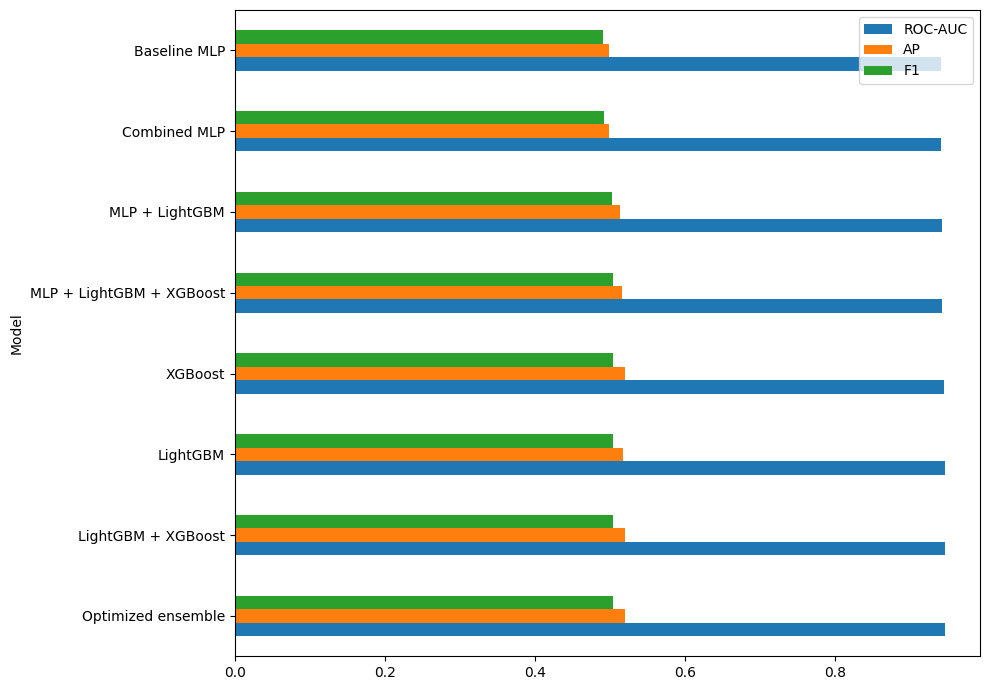

Selected by OOF: Optimized ensemble
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    137654
           1       0.56      0.46      0.50      2338

    accuracy                           0.98    139992
   macro avg       0.78      0.73      0.75    139992
weighted avg       0.98      0.98      0.98    139992



In [20]:
thresholds={name:threshold_for(y.iloc[dev],p) for name,p in oof.items()}
dev_results=pd.DataFrame([metrics(name,y.iloc[dev],p,thresholds[name]) for name,p in oof.items()]).sort_values('ROC-AUC',ascending=False)
best_name=dev_results.iloc[0]['Model']
results=pd.DataFrame([metrics(name,y.iloc[hold],p,thresholds[name]) for name,p in held.items()]).sort_values('ROC-AUC',ascending=False)
print('Development OOF (selection):'); display(dev_results)
print('Holdout (evaluation):'); display(results)
results.to_csv('ensemble_holdout_results.csv',index=False)
dev_results.to_csv('ensemble_oof_results.csv',index=False)
results.set_index('Model')[['ROC-AUC','AP','F1']].plot.barh(figsize=(10,7)); plt.tight_layout(); plt.show()
print('Selected by OOF:',best_name)
print(classification_report(y.iloc[hold],held[best_name]>=thresholds[best_name],zero_division=0))


In [21]:
assert np.array_equal(submission['id'].to_numpy(),test['id'].to_numpy())
assert np.isfinite(test_preds[best_name]).all()
submission['is_fraud']=test_preds[best_name]
submission.to_csv('submission.csv',index=False)
display(submission.head())


,id,is_fraud
0,699960,0.000220
1,699961,0.000187
2,699962,0.078556
3,699963,0.001492
4,699964,0.002139
